### Environment Setup (for Google Cloud Instance)

In [1]:
import os
os.environ['TORCH_HOME'] = '/home/liam_sbhoo/dl-lab-final-project/cache'
%cd /home/liam_sbhoo/dl-lab-final-project/

/home/liam_sbhoo/dl-lab-final-project


### Load model and preprocesses

In [2]:
from omegaconf import OmegaConf
from lavis.models import load_preprocess
from lavis.models.blip2_models.blip2_qformer import Blip2Qformer
from models.localized_blip2_qformer import LocalizedBlip2QFormer

model_type = "coco"
preprocess_cfg = OmegaConf.load(LocalizedBlip2QFormer.default_config_path(model_type)).preprocess
localized_model = LocalizedBlip2QFormer.from_pretrained(model_type=model_type).to("cuda")
full_image_model = Blip2Qformer.from_pretrained(model_type=model_type).to("cuda")
vis_preprocess, text_preprocess = load_preprocess(preprocess_cfg)


/home/shared/mambaforge/envs/localization/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Position interpolate from 16x16 to 26x26
Position interpolate from 16x16 to 26x26


### Load three sample images

In [3]:
from torch.utils.data import DataLoader
from datasets.refcoco_plus_dataset import RefCocoPlusDataset

refcoco = RefCocoPlusDataset(
        vis_root="./datasets/coco2014/coco/images",
        instances_file="./datasets/refcoco+/instances.json",
        refs_file="./datasets/refcoco+/refs(unc).p",
        set_type="val",
        vis_transform=vis_preprocess["eval"],
        text_transform=text_preprocess["eval"],
    )


dataloader = DataLoader(refcoco, batch_size=32, collate_fn=RefCocoPlusDataset.collate_fn)
data_iter = iter(dataloader)

Missing 709/49856 references for val set.


### Visualize and Compare the Captions generated (localized_model vs the full_image_model)

Helper functions for visualizing the images

In [4]:
import json
from dataclasses import dataclass
from pathlib import Path
from pprint import pprint
from typing import Tuple, List, Optional, Union

import matplotlib.pyplot as plt
from IPython.display import display
from PIL import ImageDraw, ImageFont, Image
from matplotlib import colors as mpl_colors, cm as mpl_cm
from tqdm import tqdm


def load_jsonl(file):
    data_str = Path(file).read_text(encoding="utf-8")
    data = []
    for i, line in enumerate(data_str.splitlines()):
        try:
            data.append(json.loads(line))
        except Exception as e:
            raise RuntimeError(f"Error loading json file {file} line {i}") from e
    return data


def get_bbox_bounds(box_x: float, box_y: float, box_w: float, box_h: float, image_w: int,
                    image_h: int, min_w=32, min_h=32):
    """
    Get the bounding box boundaries for cropping the image.
    Increase the box size if it is too small.

    Args:
        box_x: absolute box coordinates for the given image
        box_y:
        box_w:
        box_h:
        image_w: image size
        image_h:
        min_w: minimum box size
        min_h:

    Returns:
        Cropping parameters tuple (x1, y1, x2, y2)

    """
    # Calculate the center coordinates of the bounding box
    center_x = box_x + (box_w / 2)
    center_y = box_y + (box_h / 2)

    # Calculate the new width and height of the bounding box
    new_w = max(box_w, min_w)
    new_h = max(box_h, min_h)

    # Calculate the new x and y coordinates of the top-left corner of the bounding box
    new_x = center_x - (new_w / 2)
    new_y = center_y - (new_h / 2)

    # Adjust the new x coordinate if the box is too close to the left border
    if new_x < 0:
        new_x = 0
        new_x2 = min(new_x + new_w, image_w)
    else:
        new_x2 = min(new_x + new_w, image_w)
        if new_x2 > image_w:
            new_x2 = image_w
            new_x = max(new_x2 - new_w, 0)

    # Adjust the new y coordinate if the box is too close to the top border
    if new_y < 0:
        new_y = 0
        new_y2 = min(new_y + new_h, image_h)
    else:
        new_y2 = min(new_y + new_h, image_h)
        if new_y2 > image_h:
            new_y2 = image_h
            new_y = max(new_y2 - new_h, 0)

    # Return the cropping boundaries as integers
    return int(new_x), int(new_y), int(new_x2), int(new_y2)


def create_colormap_for_dark_background(
        n: int = 256, inverted=False, scale=1., alpha=1.,
        add_brightness: float = 0.) -> mpl_colors.Colormap:
    """
    Colormap with only light colors that works well for text on dark background.

    Args:
        n: number of discrete colors to generate in the colormap
        inverted: if True, invert the colormap (gives dark colors for bright background)
        scale: downscale the colormap (make it darker, 1.0 = no scaling)
        alpha: alpha value for all colors
        add_brightness: add this value to all color values (0.0 = no change)

    Returns:
        colormap
    """
    ccmap_colors = [
        [128, 128, 255],
        [0, 255, 255],
        [0, 255, 0],
        [255, 255, 0],
        [255, 0, 0],
        [255, 0, 255],
        [255, 255, 255]
    ]

    def _convert(c):
        c = c / 255
        if inverted:
            c = 1 - c
        c_scaled = max(min(c * scale, 1.0), 0.0)
        return c_scaled * (1.0 - add_brightness) + add_brightness

    ccmap_colors_01 = [
        [_convert(a) for a in rgb] + [alpha] for rgb in ccmap_colors
    ]
    ccmap = mpl_colors.LinearSegmentedColormap.from_list('better_nipy', ccmap_colors_01, N=n)
    return ccmap


@dataclass
class ColorGetterForColorMap:
    input_cmap: Union[mpl_colors.Colormap, str]
    start_val: Union[int, float]
    stop_val: Union[int, float]
    return_alpha: bool = False
    return_float: bool = False

    def __post_init__(self):
        self.cmap = self.input_cmap
        if isinstance(self.input_cmap, str):
            self.cmap = plt.get_cmap(self.input_cmap)
        self.norm = mpl_colors.Normalize(vmin=self.start_val, vmax=self.stop_val)
        self.scalar_map = mpl_cm.ScalarMappable(norm=self.norm, cmap=self.cmap)

    def get_color(self, val) -> Union[Tuple[int, int, int, int], Tuple[int, int, int]]:
        rgba = self.scalar_map.to_rgba(val)
        if not self.return_alpha:
            rgba = rgba[:3]
        if not self.return_float:
            rgba = [int(round(a * 255)) for a in rgba]
        return rgba


def create_colorgetter_from_colormap(input_cmap: Union[mpl_colors.Colormap, str],
                                     return_alpha: bool = False,
                                     return_float: bool = False):
    # getter is now function that takes a value in (0, 1) and returns a color
    color_helper = ColorGetterForColorMap(input_cmap, 0, 1, return_alpha=return_alpha,
                                          return_float=return_float)
    return color_helper.get_color


def draw_bounding_boxes_pil(
        image: Image.Image,
        boxes: List[Tuple[float, float, float, float]],  # x, y, w, h
        labels: Optional[List[str]] = None,
        colors: Optional[List[Tuple[int, int, int]]] = None,
        width: int = 3,
        font: str = "DejaVuSans.ttf",
        font_size: int = 14,
        cmap: Optional[Union[str, mpl_colors.Colormap]] = None,
):
    draw = ImageDraw.Draw(image)
    font = ImageFont.truetype(font, font_size)

    if colors is None:
        if cmap is None:
            cmap = create_colormap_for_dark_background(add_brightness=0.5)
        # automatically generate a bunch of colors from the colormap
        getter = create_colorgetter_from_colormap(cmap)
        colors = [tuple(getter(i / len(boxes))) for i in range(len(boxes))]

    if labels is None:
        labels = [str(i) for i in range(len(boxes))]

    for box, label, color in zip(boxes, labels, colors):
        x, y, w, h = box
        x1, y1, x2, y2 = get_bbox_bounds(x, y, w, h, image.width, image.height, min_w=0, min_h=0)
        draw.rectangle([(x1, y1), (x2, y2)], outline=color, width=width)

        text_args = dict(font=font, stroke_width=2)
        (t_left, t_top, t_right, t_bottom) = draw.textbbox((0, 0), label, **text_args)
        # text_width, text_height = draw.textsize(label, **text_args)
        text_width, text_height = t_right - t_left, t_bottom - t_top
        text_x = min(x1 + width + 2, image.width - text_width)
        text_y = min(y1 + width + 2, image.height - text_height)
        draw.text((text_x, text_y), label, fill=color, anchor="lt",
                  stroke_fill="black", **text_args)

    return image


In [5]:
from pycocotools.coco import COCO

# create COCO object
coco = COCO("./datasets/refcoco+/instances.json")    

loading annotations into memory...
Done (t=3.93s)
creating index...
index created!


In [6]:
import json

instances = json.load(open("./datasets/refcoco+/instances.json", "r"))

In [7]:
bboxes = {}
for ann in instances["annotations"]:
    bboxes[ann["id"]] = ann["bbox"]

#### Functions to visualize images, captions and attention masks

In [8]:
from copy import deepcopy

import numpy as np
import torch
from PIL import Image

def get_pil_image_by_coco_image_id(image_id: int) -> Image.Image:
    # retrieve raw image based on image_id (with its url)
    coco_image = coco.loadImgs(image_id)[0]
    filename = coco_image["file_name"]
    file_dir = filename.split("_")[1]
    filepath = os.path.join("./datasets/coco2014/coco/images", file_dir, filename)
    return Image.open(filepath)


def visualize_and_compare(batch, full_image_captions, localized_captions, att_masks, zero_mask_captions=None):
    images_with_original_bbox = []
    localized_images_with_box = []
    full_images = []

    for img_id, ann_id, box, local_cap, att_mask \
        in zip(batch["image_id"], batch["ann_id"], batch["bbox_normalized"], localized_captions, att_masks):

        raw_image = get_pil_image_by_coco_image_id(img_id)

        # retrieve bounding boxes from instances.json (just to be sure)
        original_bbox = bboxes[ann_id]
        images_with_original_bbox.append(draw_bounding_boxes_pil(deepcopy(raw_image), [original_bbox], font_size=12, width=6))

        resized_box = box * torch.tensor([raw_image.width, raw_image.height, raw_image.width, raw_image.height])
        localized_image_with_box = draw_bounding_boxes_pil(deepcopy(raw_image), [resized_box], [local_cap], font_size=12, width=6)
        localized_images_with_box.append(localized_image_with_box)

        full_images.append(raw_image)

    for original_img, localized_img, full_img, full_cap, att_mask \
        in zip(images_with_original_bbox, localized_images_with_box, full_images, full_image_captions, att_masks):
        print("------------------")
        print("full_cap:", full_cap)
        if zero_mask_captions is not None:
            print("zero_mask_cap:", zero_mask_captions.pop(0))
        # display(original_img)
        display(overlay_att_masks_on_image(localized_img, att_mask))


def overlay_att_masks_on_image(image: Image, att_mask: torch.Tensor) -> Image:
    # resize att_mask to image size
    att_mask = att_mask.view(26, 26)
    att_mask = interpolate_mask(att_mask, image.size)

    # draw att_mask on image
    att_mask = att_mask.cpu().numpy()
    att_mask = Image.fromarray((att_mask * 255).astype(np.uint8))
    att_mask = att_mask.convert("RGBA")
    image = image.convert("RGBA")
    image = Image.blend(image, att_mask, 0.2)
    return image.convert("RGB")


def interpolate_mask(mask_2d: torch.Tensor, size: Tuple[int, int]) -> torch.Tensor:
    # width = np.sqrt(mask.shape[0]).astype(int)
    # mask = mask.view(width, width)

    resized_mask = torch.zeros((size[0], size[1]))

    x_axis = torch.arange(0, size[0], 1, dtype=torch.int16)
    y_axis = torch.arange(0, size[1], 1, dtype=torch.int16)
    x_index = torch.floor(x_axis / size[0] * mask_2d.shape[1]).int()
    y_index = torch.floor(y_axis / size[1] * mask_2d.shape[0]).int()

    resized_mask = mask_2d[y_index[:, None], x_index]
            
    return resized_mask


In [11]:
mask = torch.zeros((9, 9))
mask[7:9, 5:9] = 1
mask

tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 1., 1., 1.],
        [0., 0., 0., 0., 0., 1., 1., 1., 1.]])

In [12]:
interpolate_mask(mask, (22, 22))

tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0.,

In [13]:
def get_attention_mask_based_on_norm_bbox(image_embeds, norm_bboxes):
    """
    Args:
        image_embeds (torch.Tensor): A tensor of shape (batch_size, num_patches, embed_dim).
        boxes (torch.Tensor): A tensor of shape (batch_size, 4).
    Returns:
        image_att_masks (torch.Tensor): A tensor of shape (batch_size, num_patches).
    """
    batch_size, num_patches, _ = image_embeds.shape
    
    # Assuming we are dealing with square images
    assert np.sqrt(num_patches) % 1 == 0    # Assert num_patches is a perfect square
    width = int(np.sqrt(num_patches))

    # Transform normalized bounding boxes to absolute coordinates (in patches)
    boxes = norm_bboxes * width

    # Extract individual box coordinates
    x, y, w, h = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]

    # Calculate box boundaries
    x1, y1 = x, y
    x2, y2 = x + w, y + h

    # Round the box coordinates to the nearest integer
    x1 = x1.floor().to(torch.long)
    y1 = y1.floor().to(torch.long)
    x2 = x2.ceil().to(torch.long)
    y2 = y2.ceil().to(torch.long)

    # Create the image attention masks tensor
    image_att_masks = torch.zeros((batch_size, width, width), dtype=torch.long, device=image_embeds.device)

    for i in range(batch_size):
        # Set the corresponding region within the mask to 1
        image_att_masks[i, y1[i]:y2[i], x1[i]:x2[i]] = 1

    return image_att_masks.view(batch_size, num_patches)

In [14]:
image_embeds = torch.zeros((2, 100, 1)).cuda()
norm_bboxes = torch.Tensor([
    [0.25, 0.25, 0.75, 0.6],
    [0.5, 0.25, 0.25, 0.25],
]).cuda()

get_attention_mask_based_on_norm_bbox(image_embeds, norm_bboxes).view(2, 10, 10)

tensor([[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]],

        [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 1, 1, 1, 0, 0],
         [0, 0, 0, 0, 0, 1, 1, 1, 0, 0],
         [0, 0, 0, 0, 0, 1, 1, 1, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]], device='cuda:0')

#### Generate captions and visualize them

/home/shared/mambaforge/envs/localization/lib/python3.10/site-packages/torch/utils/checkpoint.py:31: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn("None of the inputs have requires_grad=True. Gradients will be None")


------------------
full_cap: a bowl filled with carrots and brussel sprouts


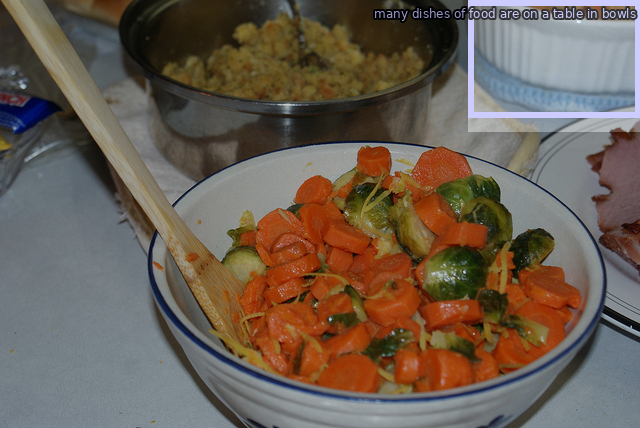

------------------
full_cap: a bowl filled with carrots and brussel sprouts


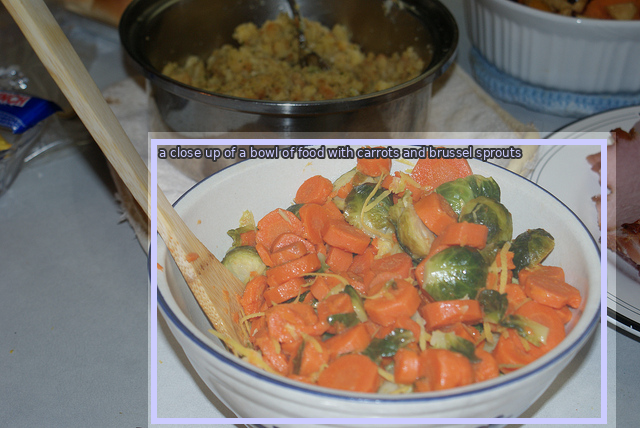

------------------
full_cap: a couple of men sitting next to each other at a table


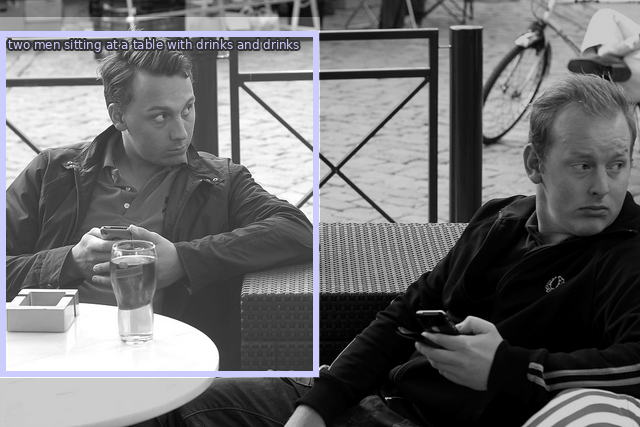

------------------
full_cap: a couple of people that are playing a video game


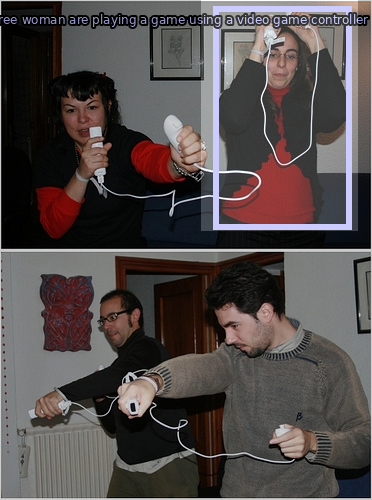

------------------
full_cap: a couple of people that are playing a video game


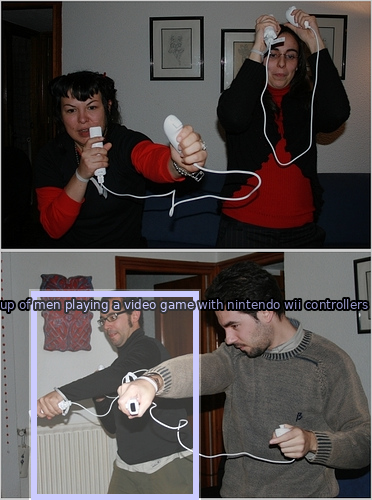

------------------
full_cap: a couple of people that are playing a video game


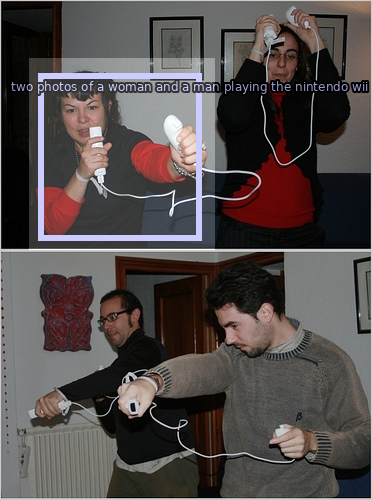

------------------
full_cap: a couple of people that are playing a video game


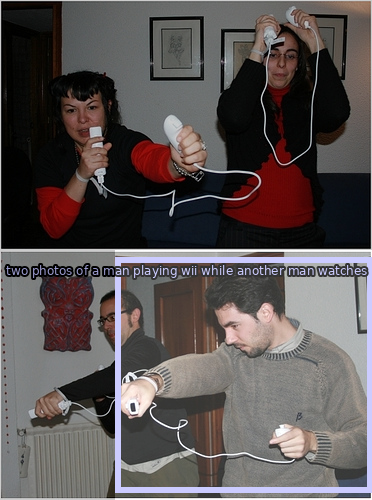

------------------
full_cap: a black cat sitting under a kitchen sink under a faucet


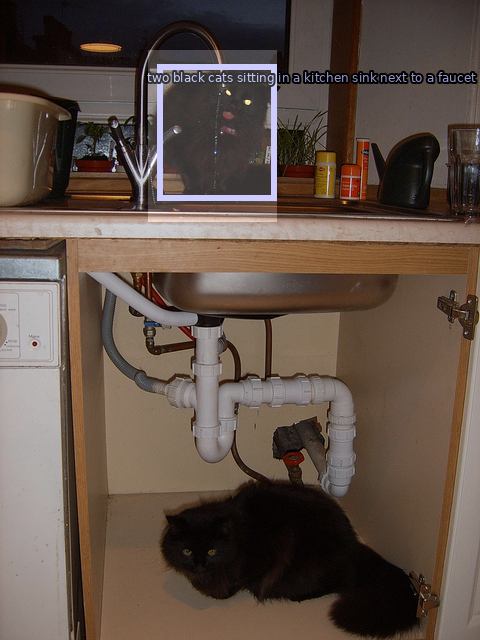

------------------
full_cap: a black cat sitting under a kitchen sink under a faucet


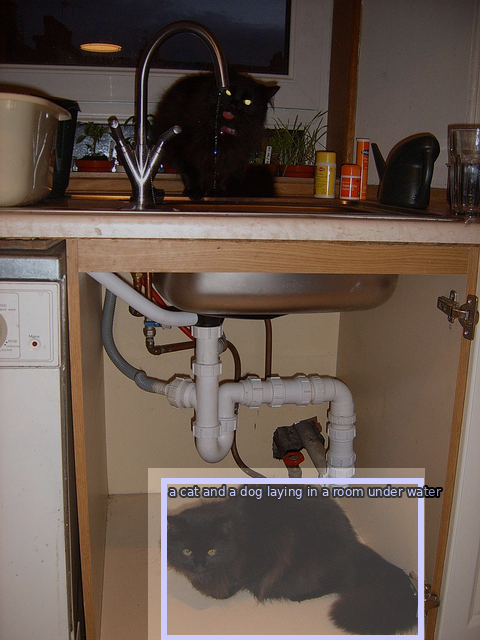

------------------
full_cap: a young girl standing next to an elephant behind a fence


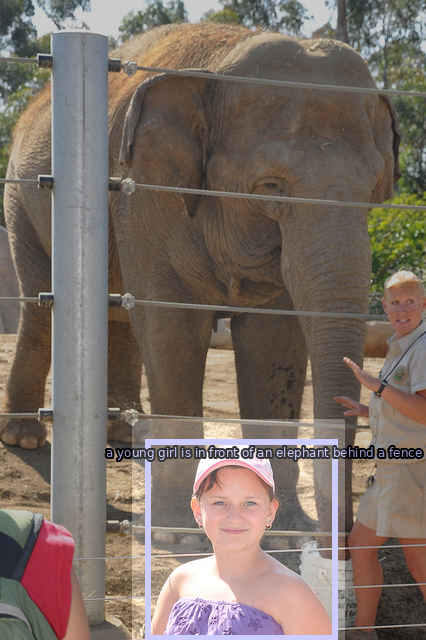

------------------
full_cap: a young girl standing next to an elephant behind a fence


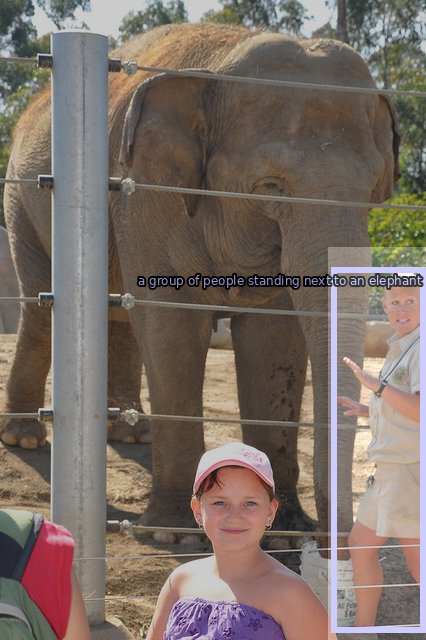

------------------
full_cap: a group of children sitting at a table eating food


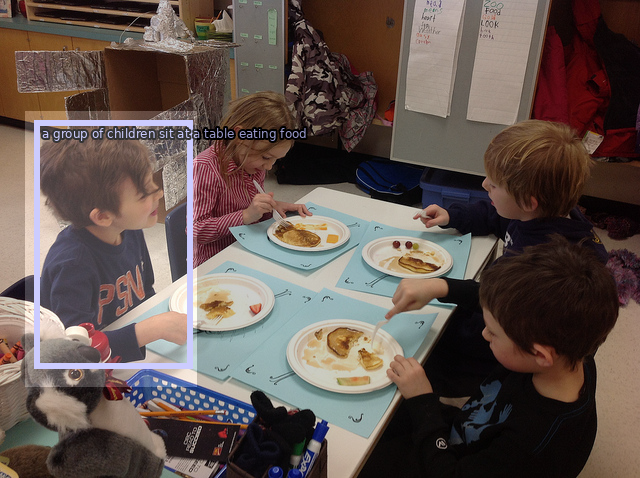

------------------
full_cap: a group of children sitting at a table eating food


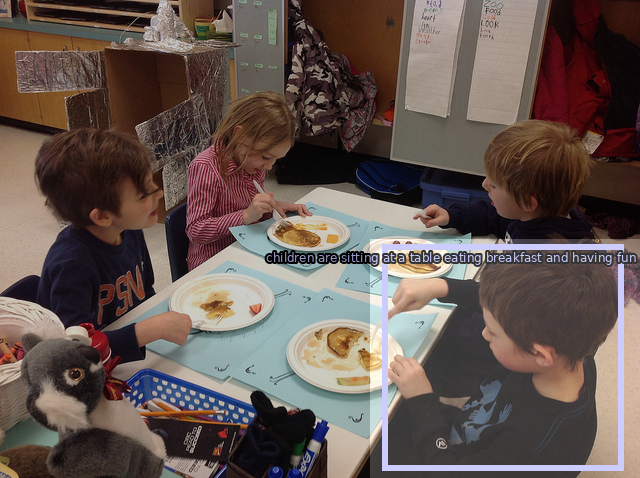

------------------
full_cap: a group of children sitting at a table eating food


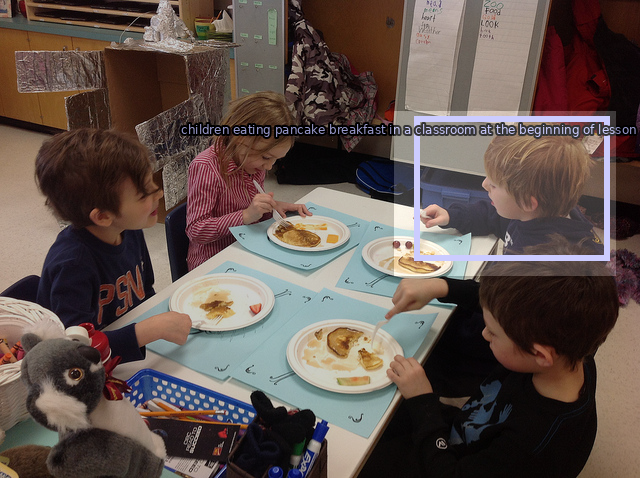

------------------
full_cap: a group of children sitting at a table eating food


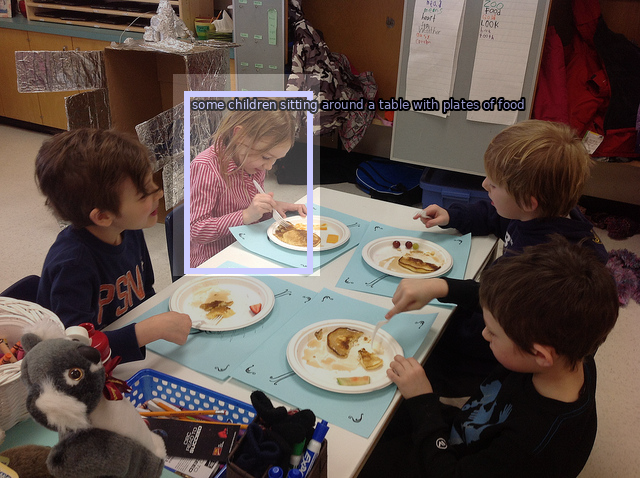

------------------
full_cap: a couple sleeping in bed next to an alarm clock


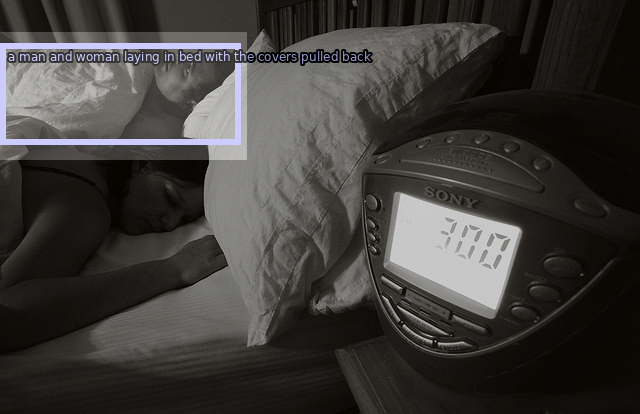

------------------
full_cap: a couple sleeping in bed next to an alarm clock


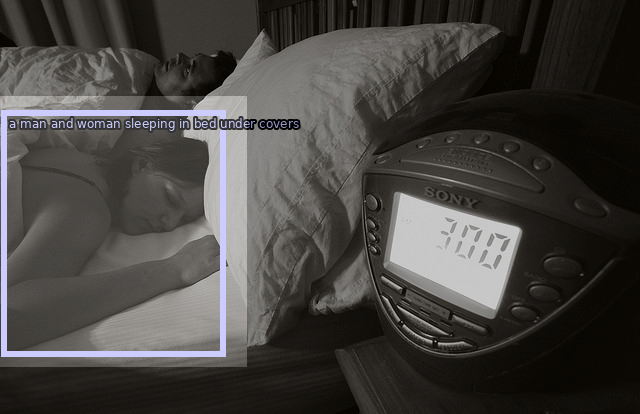

------------------
full_cap: two people holding sandwiches wrapped in paper with cucumbers and cilantro


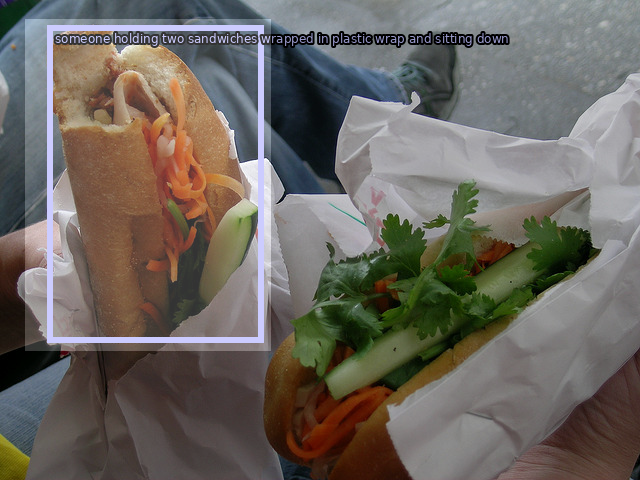

------------------
full_cap: two people holding sandwiches wrapped in paper with cucumbers and cilantro


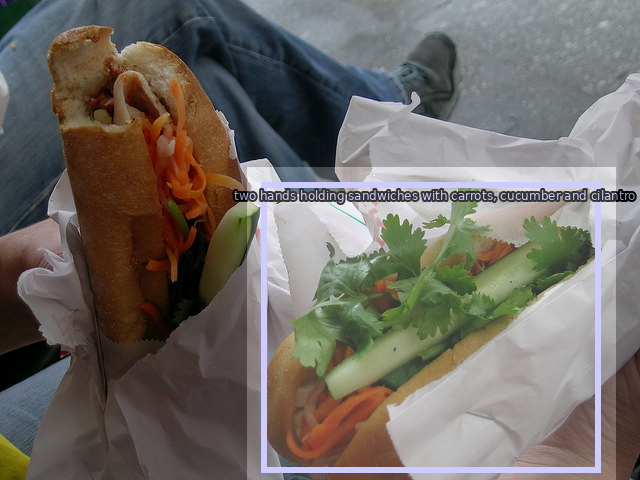

------------------
full_cap: a young girl brushing her teeth in a bathroom


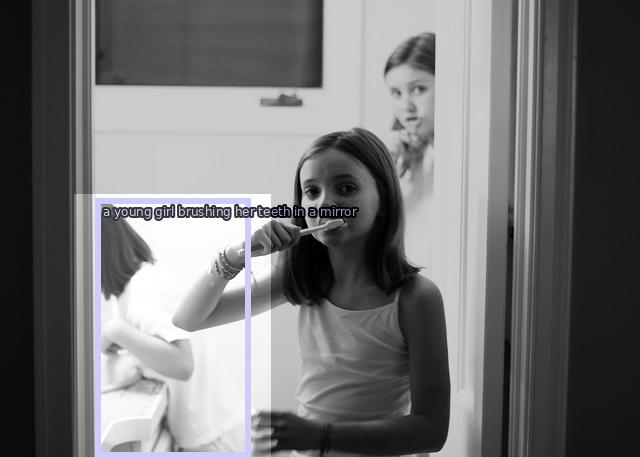

------------------
full_cap: a young girl brushing her teeth in a bathroom


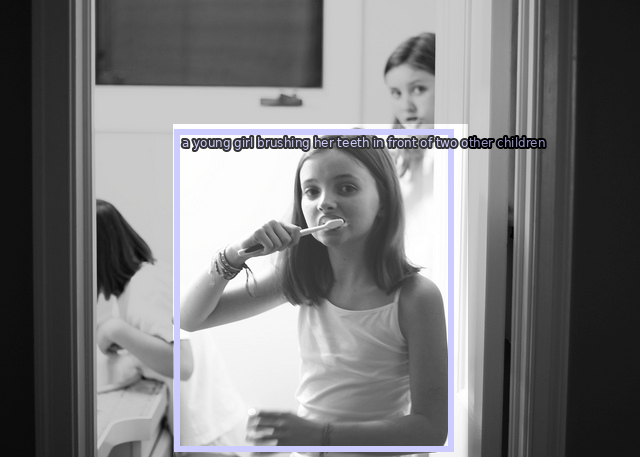

------------------
full_cap: a man swinging a tennis racquet on a tennis court


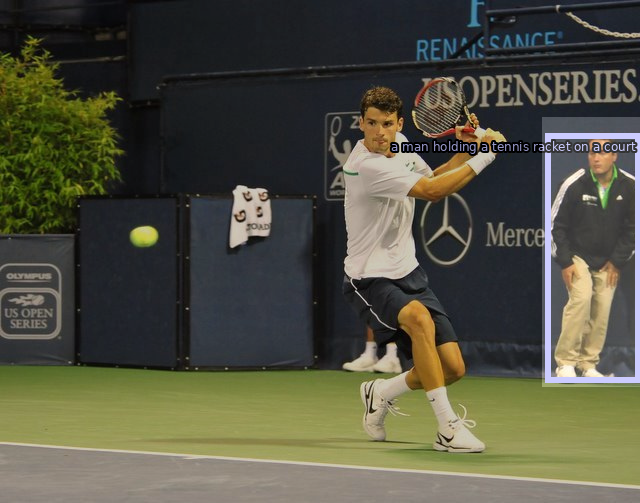

------------------
full_cap: a man swinging a tennis racquet on a tennis court


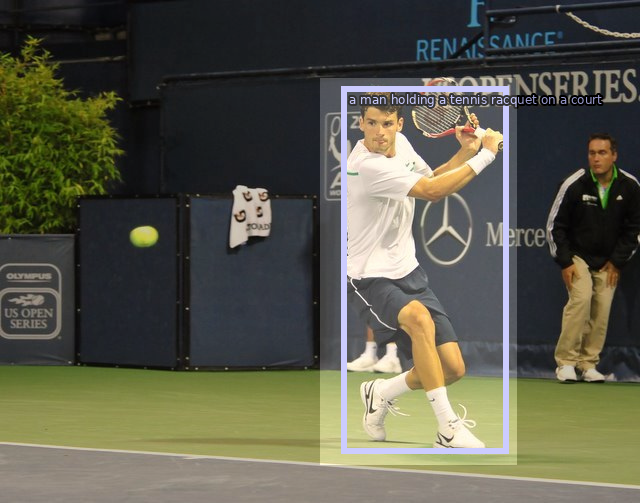

------------------
full_cap: a man standing next to a woman on a street


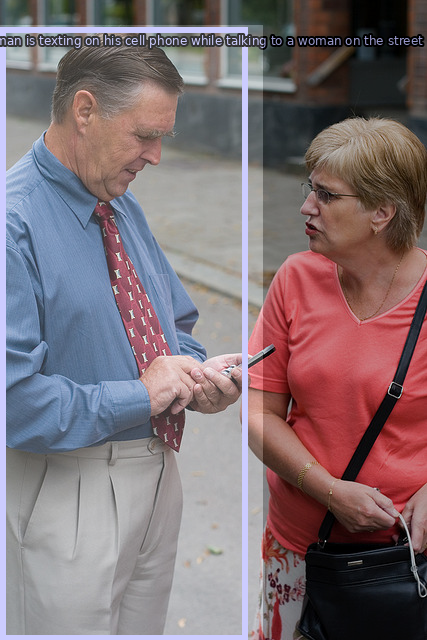

------------------
full_cap: a man standing next to a woman on a street


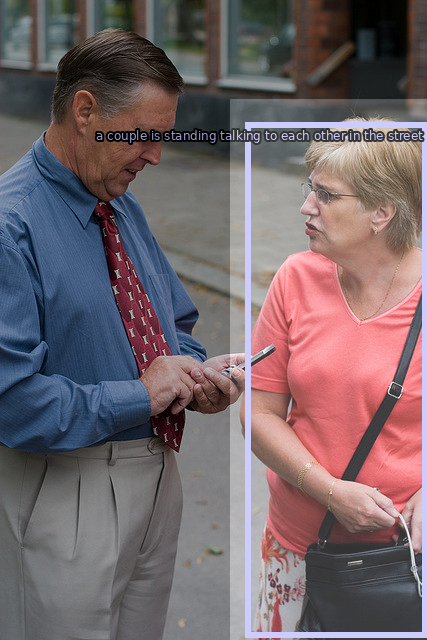

------------------
full_cap: a man and a woman standing next to each other eating food


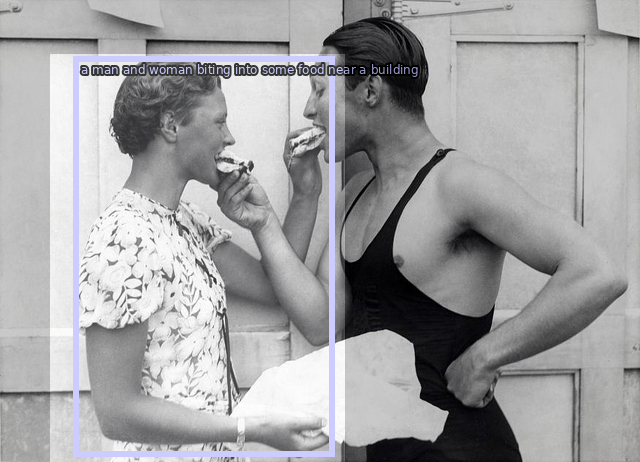

------------------
full_cap: a man and a woman standing next to each other eating food


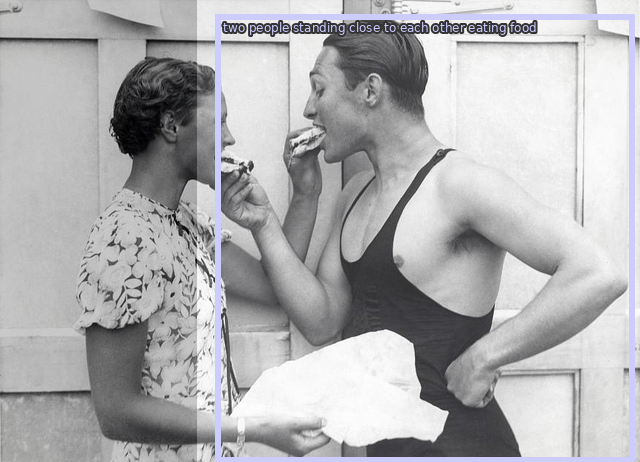

------------------
full_cap: four black suitcases lined up in front of a window


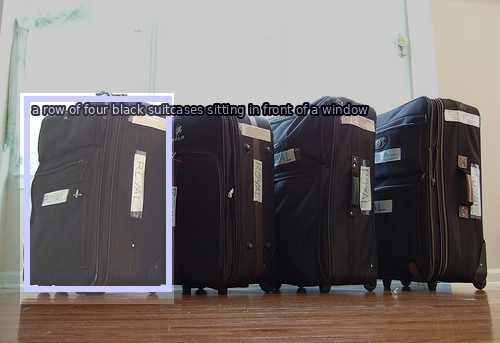

------------------
full_cap: four black suitcases lined up in front of a window


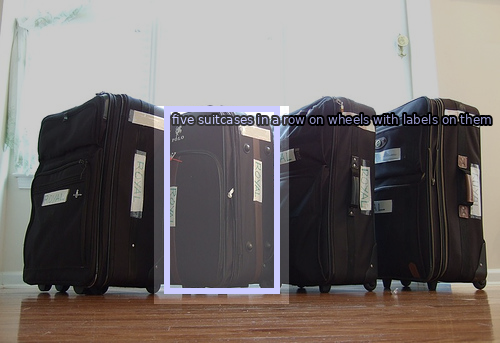

------------------
full_cap: four black suitcases lined up in front of a window


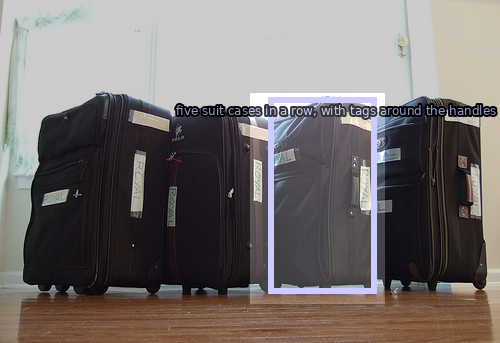

------------------
full_cap: four black suitcases lined up in front of a window


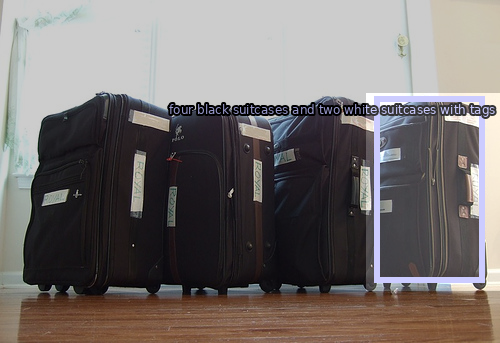

------------------
full_cap: two motorcycles are parked on the side of the road


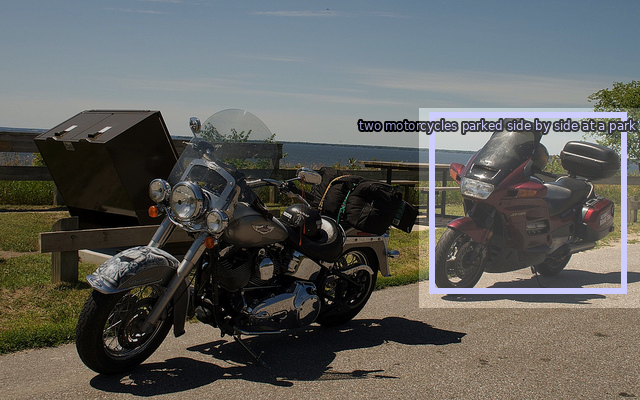

In [9]:
batch = next(data_iter)
localized_captions, att_masks = localized_model.generate(batch, return_attention_masks=True)
image_att = att_masks[:, 1:]
# zero_mask_captions = localized_model.generate(batch, zero_attention=True)
full_image_captions = full_image_model.generate(batch)
visualize_and_compare(batch, full_image_captions, localized_captions, image_att)
# visualize_and_compare(batch, full_image_captions, localized_captions, zero_mask_captions)

------------------
full_cap: two motorcycles are parked on the side of the road


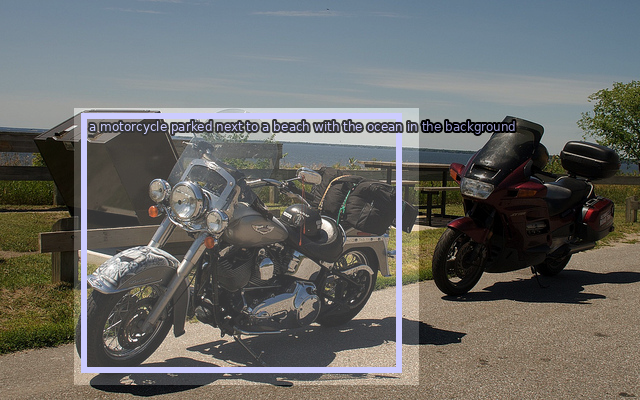

------------------
full_cap: two plates with sandwiches and a bowl of berries


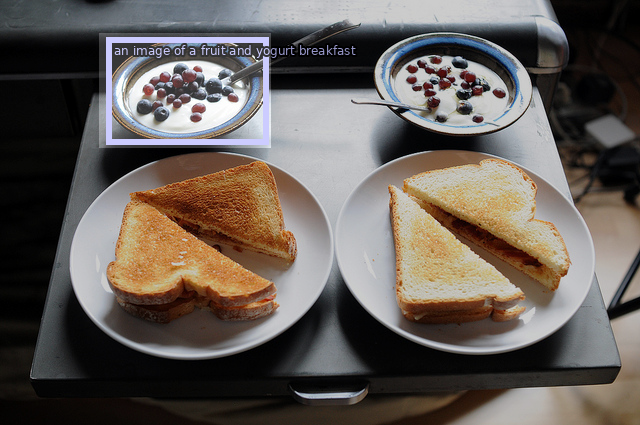

------------------
full_cap: two plates with sandwiches and a bowl of berries


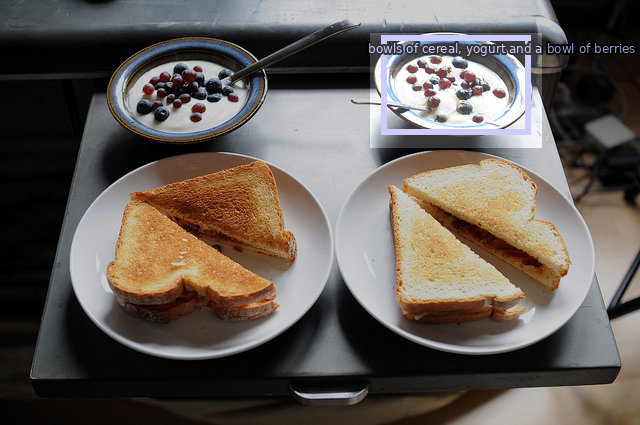

------------------
full_cap: two plates with sandwiches and a bowl of berries


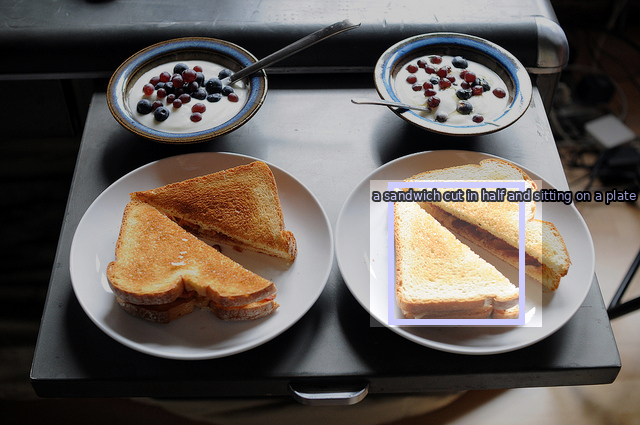

------------------
full_cap: two plates with sandwiches and a bowl of berries


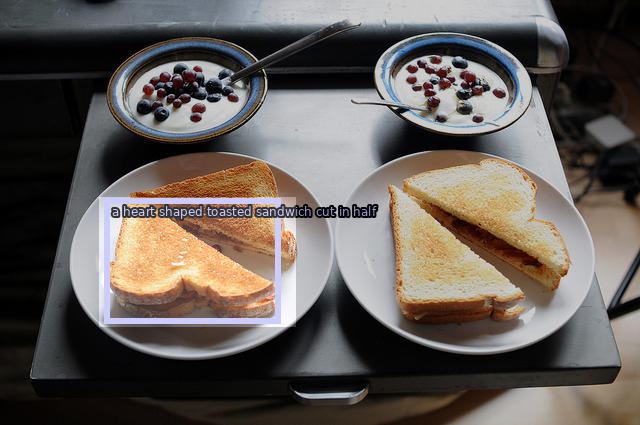

------------------
full_cap: a baseball player holding a bat on top of a field


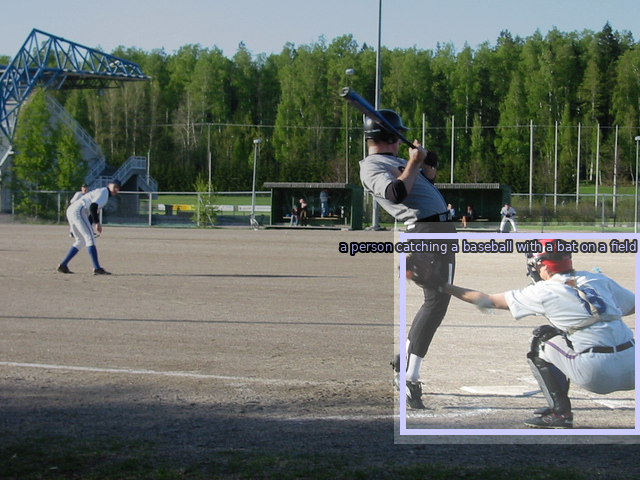

------------------
full_cap: a baseball player holding a bat on top of a field


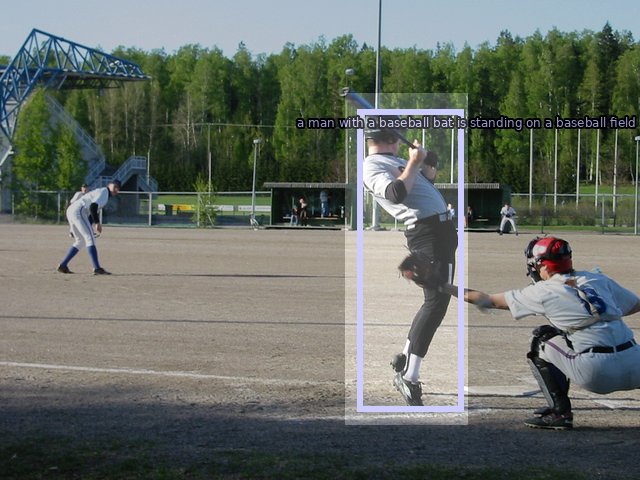

------------------
full_cap: a group of people sitting around a table with laptops


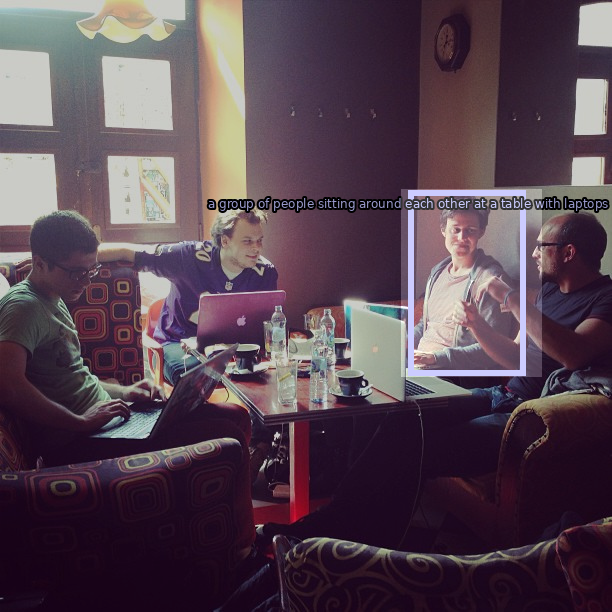

------------------
full_cap: a group of people sitting around a table with laptops


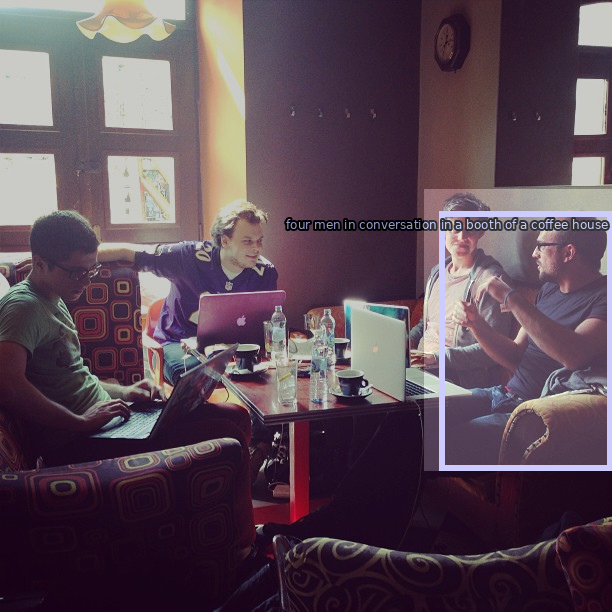

------------------
full_cap: a group of people sitting around a table with laptops


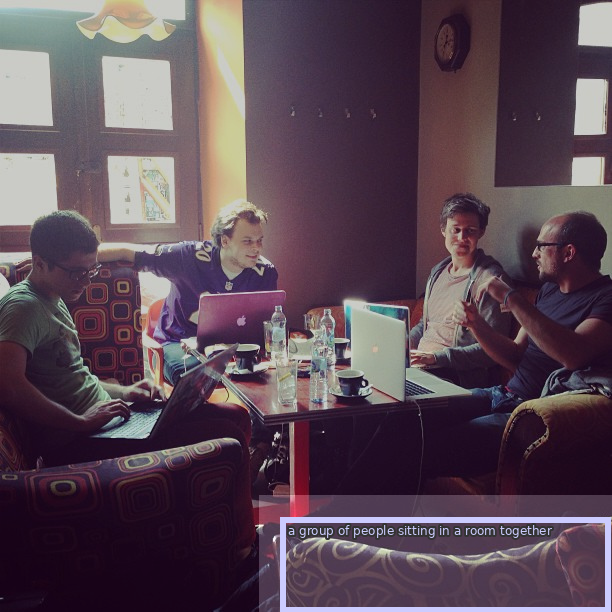

------------------
full_cap: a group of people sitting around a table with laptops


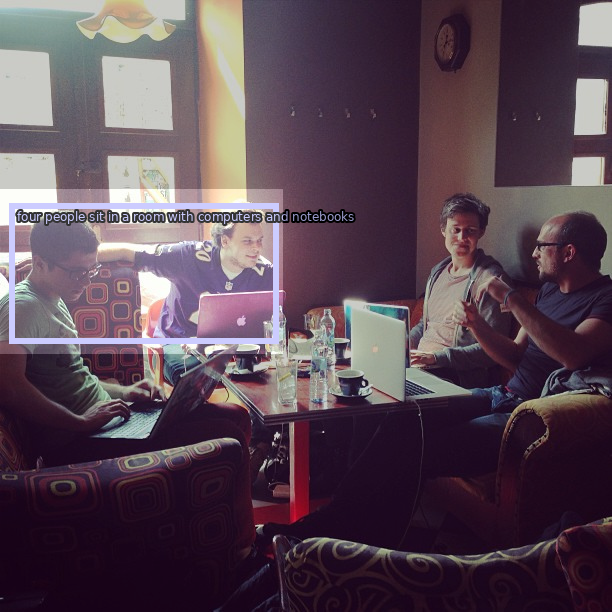

------------------
full_cap: a group of people sitting around a table with laptops


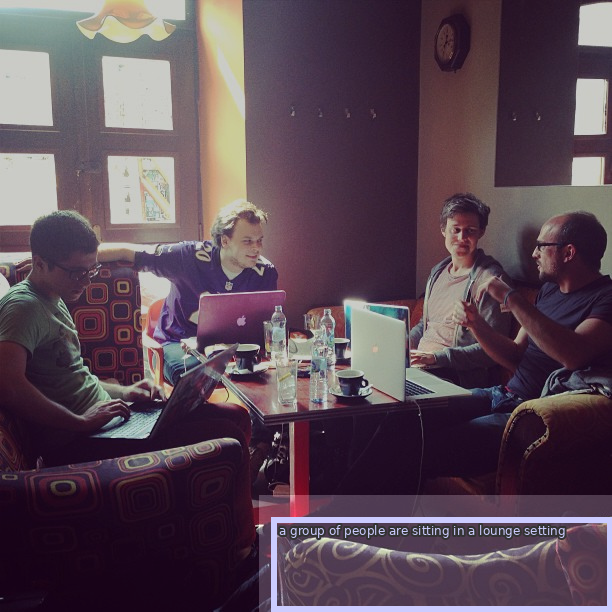

------------------
full_cap: a group of people sitting around a table with laptops


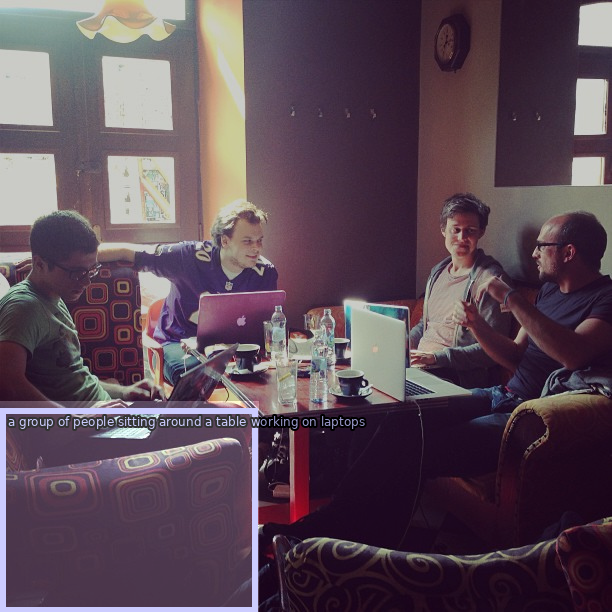

------------------
full_cap: a group of people sitting around a table with laptops


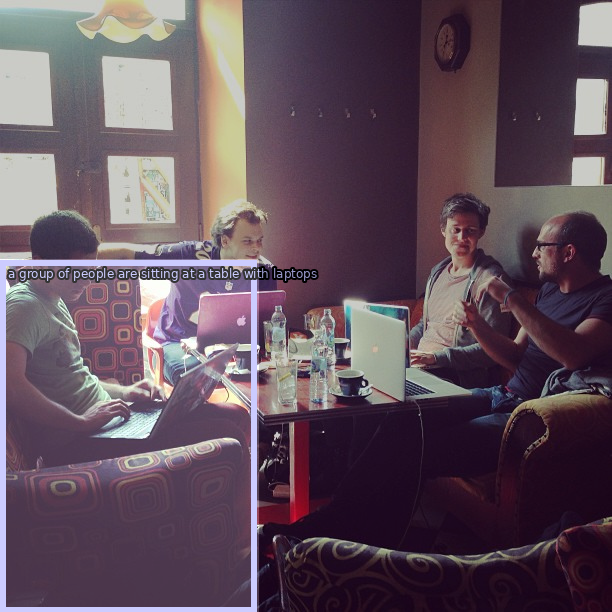

------------------
full_cap: a group of people sitting around a table with laptops


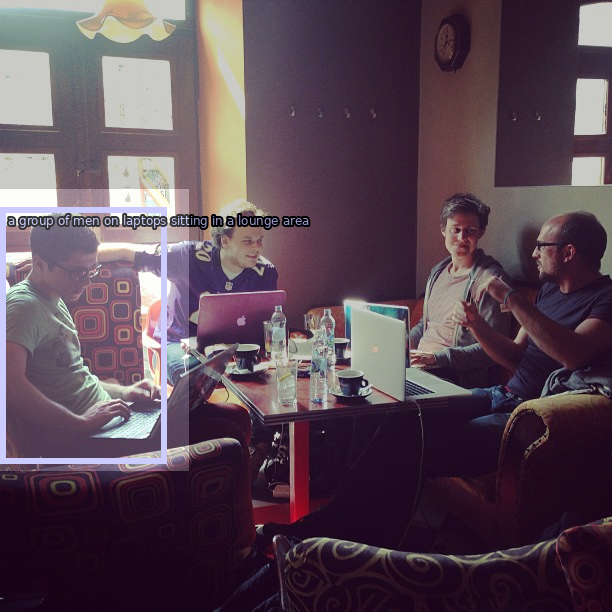

------------------
full_cap: a group of people sitting around a table with laptops


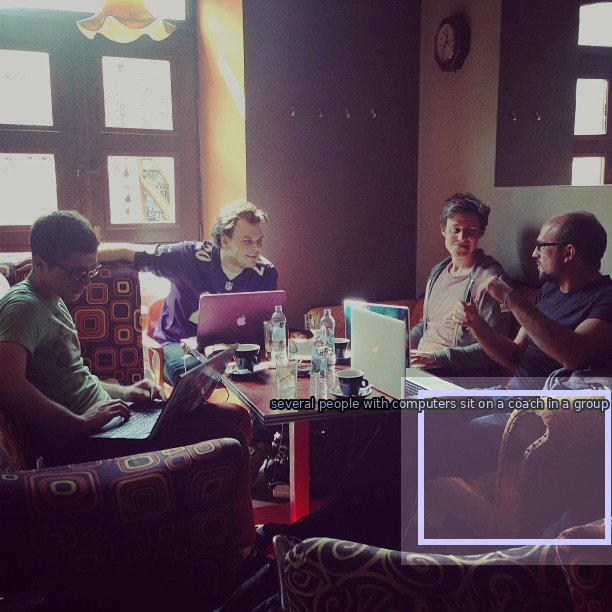

------------------
full_cap: a cat laying on its back on a chair


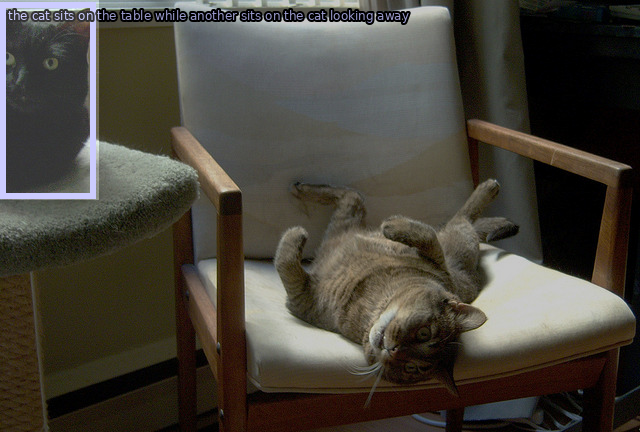

------------------
full_cap: a cat laying on its back on a chair


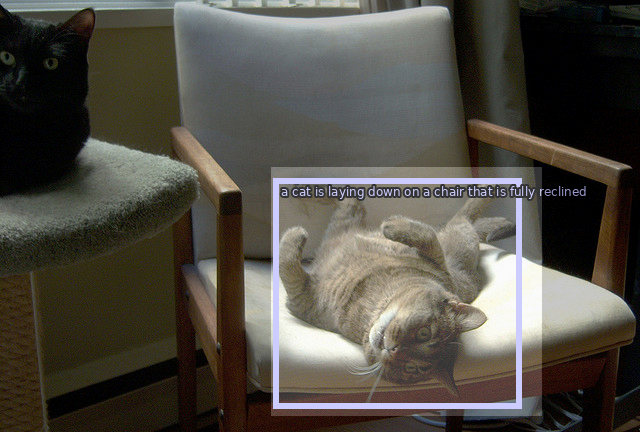

------------------
full_cap: a row of buses parked on top of a grass covered field


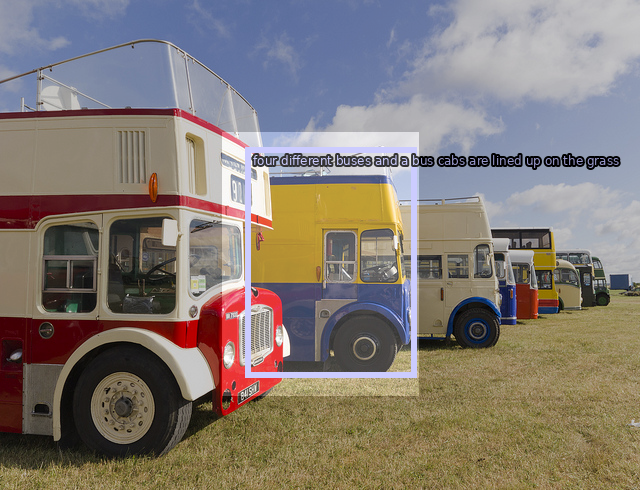

------------------
full_cap: a row of buses parked on top of a grass covered field


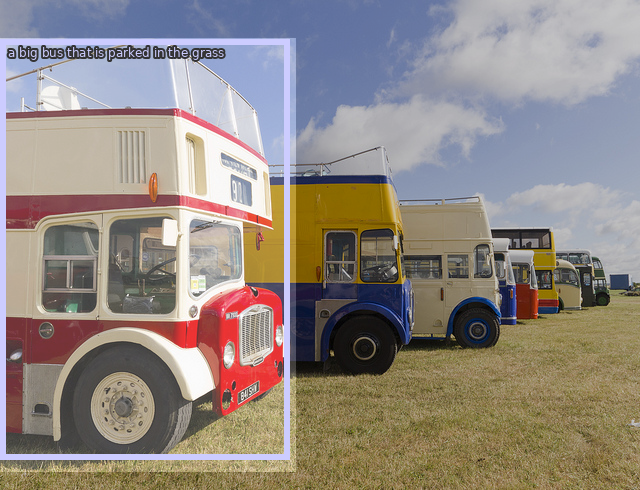

------------------
full_cap: a row of buses parked on top of a grass covered field


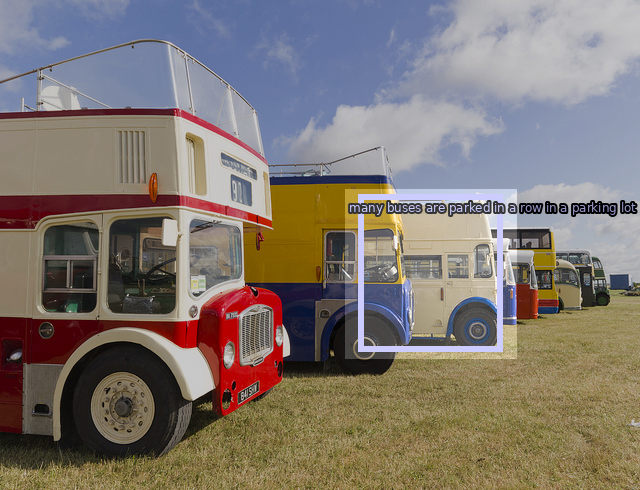

------------------
full_cap: a baseball player standing on top of a baseball field


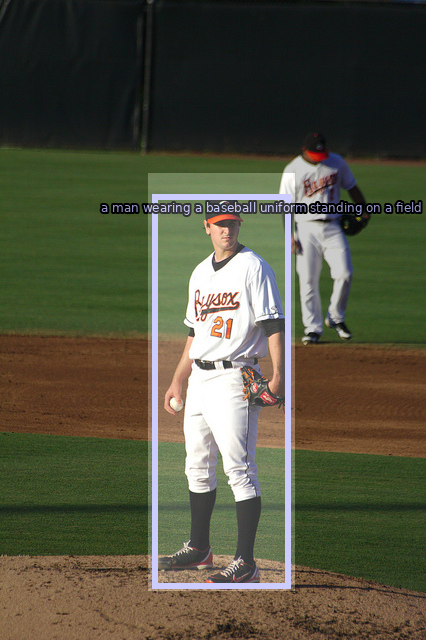

------------------
full_cap: a baseball player standing on top of a baseball field


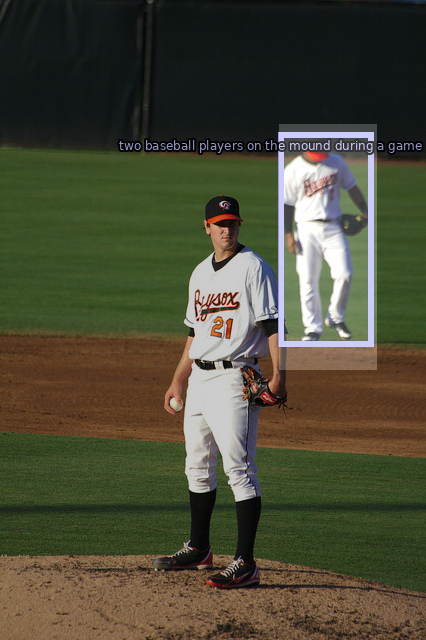

------------------
full_cap: a bowl of mixed vegetables on a black background


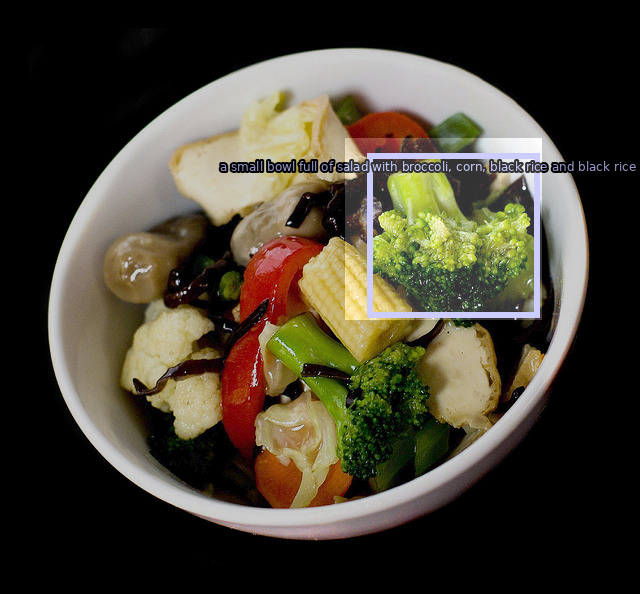

------------------
full_cap: a bowl of mixed vegetables on a black background


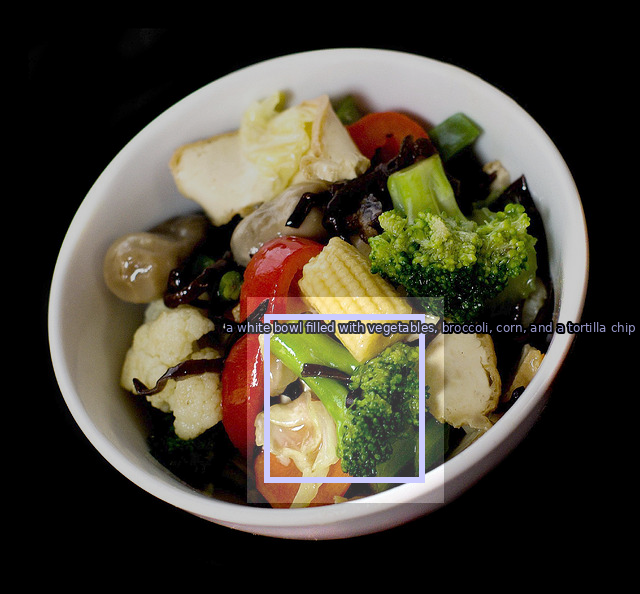

------------------
full_cap: a couple of elephants walking down a dirt road


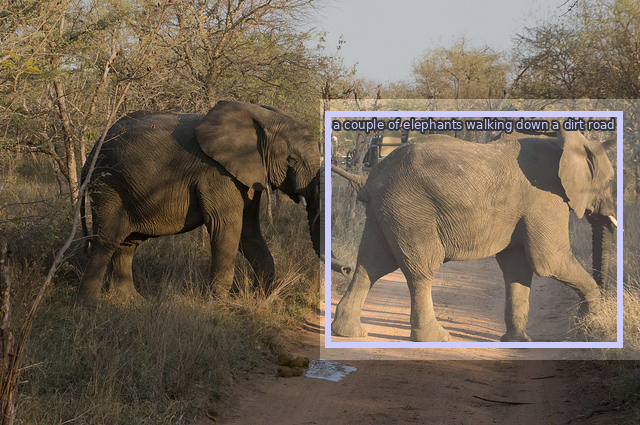

------------------
full_cap: a couple of elephants walking down a dirt road


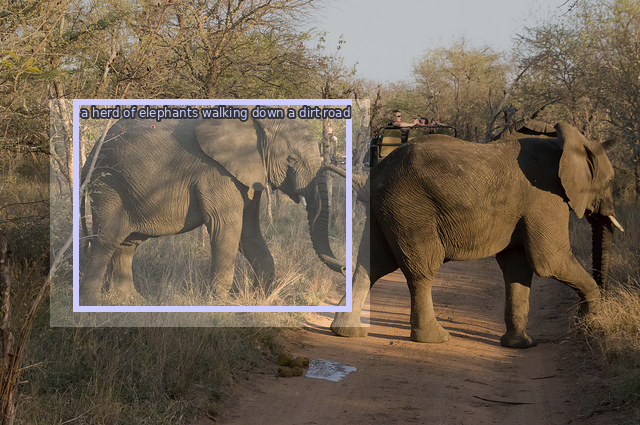

------------------
full_cap: a group of young men standing next to each other on a field


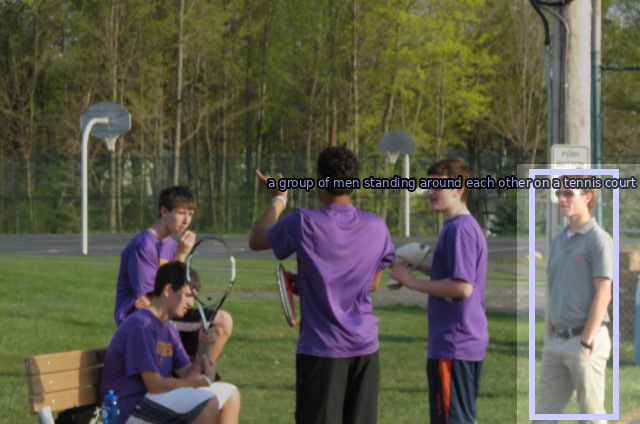

------------------
full_cap: a group of young men standing next to each other on a field


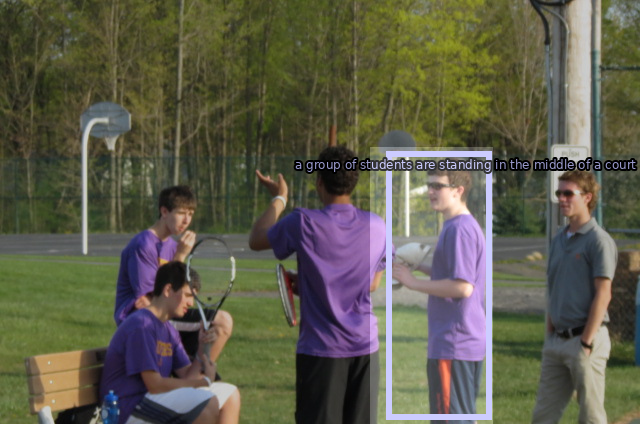

------------------
full_cap: a group of young men standing next to each other on a field


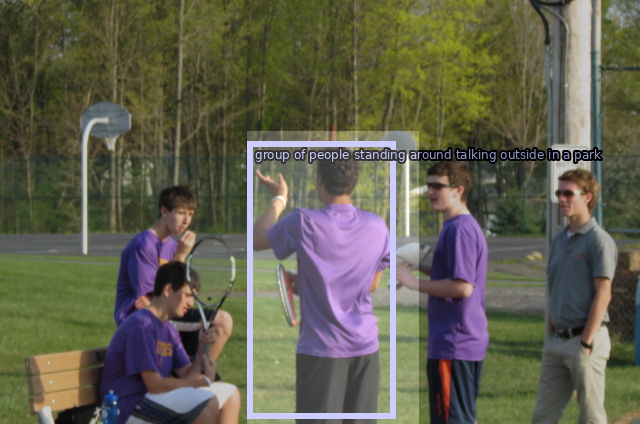

------------------
full_cap: a group of young men standing next to each other on a field


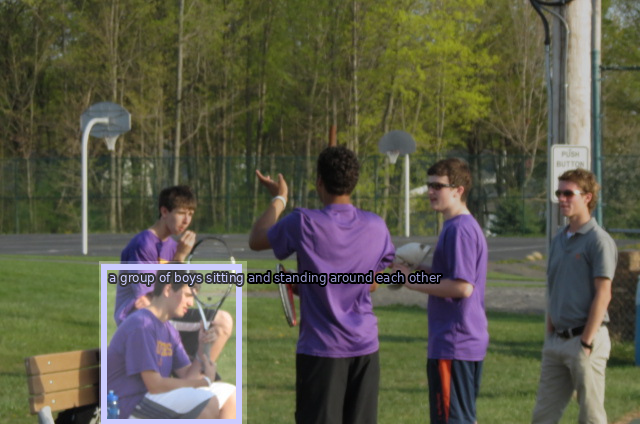

------------------
full_cap: a person holding a hot dog in their hand


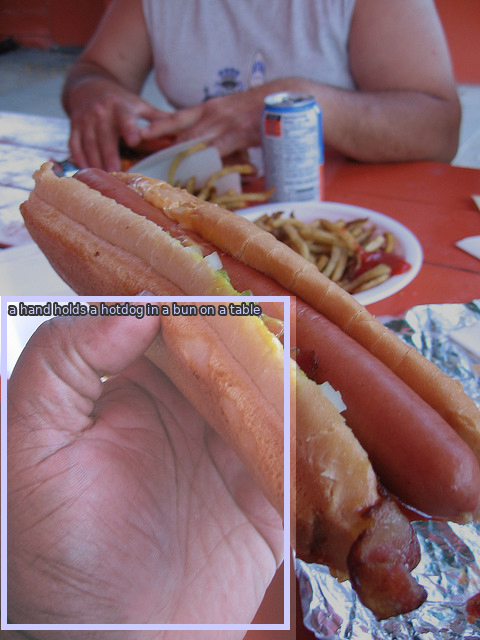

In [15]:
batch = next(data_iter)
localized_captions, att_masks = localized_model.generate(batch, return_attention_masks=True)
image_att = att_masks[:, 1:]
# zero_mask_captions = localized_model.generate(batch, zero_attention=True)
full_image_captions = full_image_model.generate(batch)
visualize_and_compare(batch, full_image_captions, localized_captions, image_att)
# visualize_and_compare(batch, full_image_captions, localized_captions, zero_mask_captions)

In [10]:
torch.set_printoptions(profile="full", linewidth=100)
image_att.view(-1, 26, 26)

tensor([[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0,